
# Alternative Solvers (Scipy and Petsc)
Here we look at different ways of solving PDEs using external
packages.
Different linear algebra backends can be accessed by changing setting the
`storage` parameter during construction of the discrete space. All
discrete functions and operators/schemes based on this space will then
use this backend. Available backends are `numpy,istl,petsc`. The default is
`numpy` which uses simple data structures and linear solvers implemented in
the `dune-fem` package - these backends were discussed
[in the previously section](solversInternal_nb.ipynb).

As discussed there, a degrees of freedom
vector (dof vector) can be retrieved from a discrete function over the
`numpy` space by using the `as_numpy` method. Similar methods are available
for the other storages, i.e., `as_istl,as_petsc`. The same methods are
also available to retrieve the underlying matrix structures of linear
operators.

We start with the same setup as used [in the previously section](solversInternal_nb.ipynb):

In [1]:
import numpy

from dune.grid import structuredGrid as leafGridView
from dune.fem.space import lagrange
from dune.fem.scheme import galerkin
from dune.fem.function import gridFunction
from dune.fem import integrate
from dune.ufl import Constant
from ufl import TestFunction, TrialFunction, SpatialCoordinate, FacetNormal, \
                dx, ds, div, grad, dot, inner, exp, sin, conditional

gridView = leafGridView([0, 0], [1, 1], [12, 12])
space = lagrange(gridView, order=2)
u_h = space.interpolate(0, name='u_h')

x,u,v,n = ( SpatialCoordinate(space), TrialFunction(space), TestFunction(space), FacetNormal(space) )
exact = 1/2*(x[0]**2+x[1]**2) - 1/3*(x[0]**3 - x[1]**3) + 1

a  = ( inner(grad(u),grad(v)) + (1+u)**2*u*v ) * dx
bf = (-div(grad(exact)) + (1+exact)**2*exact) * v * dx
bg = dot(grad(exact),n)*v*ds

# simple function to show the result of a simulation
def printResult(method,error,info):
    print(method,"L^2, H^1 error:",'{:0.5e}, {:0.5e}'.format(
                 *[ numpy.sqrt(e) for e in integrate([error**2,inner(grad(error),grad(error))]) ]),
          "\n\t","solver info=",info,flush=True)

Having defined the model, we can now construct an `operator`. We will
use the `galerkin` operator from `dune.fem.operator` instead of the
`scheme` used so far, since we do not need the `solve` method since we
want to use external solvers in this section:

In [2]:
from dune.fem.operator import galerkin
operator = galerkin(a - (bf+bg))

## Accessing underlying data structures

The most important step is accessing the data structures setup on the C++
side in Python. In this case we would like to use the underlying dof vector from
a discrete function as numpy arrays and system matrices assembled by the
schemes and operators as scipy sparse matrices.
In the [introduction](dune-fempy_nb.ipynb) we already discussed the `as_numpy` method.
So

In [3]:
vecu_h = u_h.as_numpy

provides access to the underlying dof vector without copying. So changes
to the numpy array `vecu_h` carries over to the discrete function `u_h`.
Just remember to make changes using `vecu_h[:]` to change the actual
memory buffer.

An instance of `dune.fem.operator` describing an operator `L`
provides a method `linear` which returns an object that
stores a sparse matrix structure. The object describes the operator
linearized around zero.
To linearize around a different value use the `jacobian` method on the
`operator` that linearized
the the operator `L` around a given grid function `ubar` and fills the
linear operator structure passed in as second argument. It is also
possible to pass ``assemble=False`` to the ``linear`` method to avoid an
the linearization around zero to reduce computational cost:

In [4]:
linOp = operator.linear()                  # linearized around 0
linOp = operator.linear(assemble=False)    # empty (non valid) linear operator
operator.jacobian(space.zero, linOp)       # linearized around zero

Here we linearize around zero. But that argument could be any grid
function. A second version of this method will return an addition
discrete function `rhs` which equals `-L[ubar]` such that `DL[ubar](u-ubar) - rhs` are the first
terms in the Taylor expansion of the operator `L`:

In [5]:
rhs = u_h.copy()
operator.jacobian(u_h, linOp, rhs)

One can now easily access the underlying sparse matrix by again using
`as_numpy` (and again the underlying data buffers are not copied):

In [6]:
A = linOp.as_numpy
print(type(A))
# plt.spy(A, precision=1e-8, markersize=1)

<class 'scipy.sparse._csr.csr_matrix'>


## Defining discrete function with given external dof vector

As a last step we sometimes need to construct a discrete function based
on a given dof vector. Here a simple example where we use a `numpy`
random vector as dof vector for a discrete function:

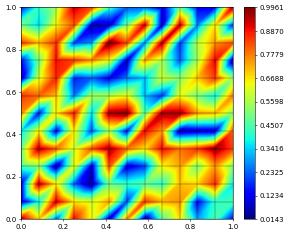

In [7]:
v_coeff = numpy.random.rand(space.size)
vh = space.function("random", dofVector=v_coeff)
vh.plot()

Again the dof vector is not copied so changing the `numpy` array will
directly change the discrete function

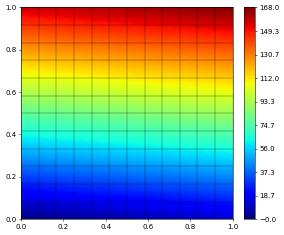

In [8]:
v_coeff[range(space.size)] = range(space.size)
vh.plot()

Now we have all the ingredients to write a simple Newton solver to solve
our non-linear time dependent PDE.

.. index::
   pair: Solvers; Scipy

## Using Scipy
In our first example, we implement a simple Newton Krylov solver using a linear solver from
Scipy. We can use the `as_numpy` method to access the degrees of freedom as
Numpy vector based on the `python buffer protocol`. So no data is copied
and changes to the dofs made on the Python side are automatically carried
over to the C++ side.

In [9]:
import numpy as np
from scipy.sparse.linalg import spsolve as solver
class Scheme1:
    def __init__(self, op):
        self.model = op.model
        self.jacobian = op.linear()
        self.op = op

    def solve(self, target):
        # create a copy of target for the residual
        res = target.copy(name="residual")

        # extract numpy vectors from target and res
        sol_coeff = target.as_numpy
        res_coeff = res.as_numpy

        n = 0
        while True:
            self.op(target, res)
            absF = numpy.sqrt( np.dot(res_coeff,res_coeff) )
            if absF < 1e-6:
                break
            self.op.jacobian(target,self.jacobian)
            sol_coeff -= solver(self.jacobian.as_numpy, res_coeff)
            n += 1
        return {"iterations":n, "linear_iterations":n} # direct linear solver requires no additional iterations

scheme1_cls = Scheme1(operator)
u_h.clear()
info = scheme1_cls.solve(target=u_h)
printResult("Scipy-1",u_h-exact,info)

Scipy-1 L^2, H^1 error: 9.39196e-06, 7.32010e-04 
	 solver info= {'iterations': 8, 'linear_iterations': 8}


We can also use a non linear solver from the Scipy package

In [10]:
from scipy.optimize import newton_krylov
from scipy.sparse.linalg import LinearOperator
from scipy.sparse.linalg import cg as solver

class Scheme2:
    def __init__(self, op):
        self.op = operator
        self.model = op.model
        self.res = u_h.copy(name="residual")
        self.n = 0

    # non linear function
    def f(self, x_coeff):
        # the following converts a given numpy array
        # into a discrete function over the given space
        x = space.function("tmp", dofVector=x_coeff)
        self.op(x, self.res)
        self.n += 1
        return self.res.as_numpy

    # class for the derivative DS of S
    class Df(LinearOperator):
        def __init__(self, op, x_coeff):
            self.op = op
            self.shape = (x_coeff.shape[0], x_coeff.shape[0])
            self.dtype = x_coeff.dtype
            x = space.function("tmp", dofVector=x_coeff)
            self.jacobian = self.op.linear()
            self.update(x_coeff,None)
        # reassemble the matrix DF(u) given a DoF vector for u
        def update(self, x_coeff, f):
            x = space.function("tmp", dofVector=x_coeff)
            self.op.jacobian(x, self.jacobian)
        # compute DS(u)^{-1}x for a given DoF vector x
        def _matvec(self, x_coeff):
            return solver(self.jacobian.as_numpy, x_coeff, rtol=1e-10, atol=1e-10)[0]

    def solve(self, target):
        sol_coeff = target.as_numpy
        # call the newton krylov solver from scipy
        sol_coeff[:] = newton_krylov(self.f, sol_coeff,
                    f_tol=1e-6,
                    inner_M=self.Df(self.op,sol_coeff))
        return {"iterations":self.n, "linear_iterations":-1} # not keeping track of linear iterations

scheme2_cls = Scheme2(operator)
u_h.clear()
info = scheme2_cls.solve(target=u_h)
printResult("Scipy-2",u_h-exact,info)

Scipy-2 L^2, H^1 error: 9.39201e-06, 7.32010e-04 
	 solver info= {'iterations': 409, 'linear_iterations': -1}


.. index::
   pair: Solvers; Petsc4Py

## Using Petsc4Py
The following requires that a PETSc installation was found during the
configuration of ``dune``. Furthermore the Python package ``petsc4py`
is required:

In [11]:
from dune.common.checkconfiguration import assertCMakeHave, ConfigurationError
try:
    assertCMakeHave("HAVE_PETSC")
    petsc = True
except ConfigurationError:
    print("Dune not configured with petsc - skipping example")
    petsc = False
try:
    import sys
    import petsc4py
    petsc4py.init(sys.argv)
    from petsc4py import PETSc
except ModuleNotFoundError:
    print("petsc4py module not found -- skipping example")
    petsc4py = None

To use `petsc4py` we need to which to a storage based on the PETSc package
using the ``storage`` argument to the space constructor.

Implementing a Newton Krylov solver using the binding provided by
`petsc4py` is now straightforward:

In [12]:
if petsc4py is not None and petsc:
    spacePetsc = lagrange(gridView, order=2, storage='petsc')
    u_h = spacePetsc.interpolate(0, name='u_h')
    schemePetsc = galerkin(a==bf+bg, domainSpace=spacePetsc,rangeSpace=spacePetsc)

    class Scheme3:
        def __init__(self, scheme):
            self.model = scheme.model
            self.jacobian = scheme.linear()
            self.ksp = PETSc.KSP()
            self.ksp.create(PETSc.COMM_WORLD)
            # use conjugate gradients method
            self.ksp.setType("cg")
            # and incomplete Cholesky
            self.ksp.getPC().setType("icc")
            self.ksp.setOperators(self.jacobian.as_petsc)
            self.ksp.setFromOptions()
        def solve(self, target):
            res = target.copy(name="residual")
            sol_coeff = target.as_petsc
            res_coeff = res.as_petsc
            n = 0
            while True:
                schemePetsc(target, res)
                absF = numpy.sqrt( res_coeff.dot(res_coeff) )
                if absF < 1e-6:
                    break
                schemePetsc.jacobian(target, self.jacobian)
                self.ksp.solve(res_coeff, res_coeff)
                sol_coeff -= res_coeff
                n += 1
            return {"iterations":n, "linear_iterations":-1} # not keeping track of linear iterations

    u_h.interpolate(0)
    scheme3_cls = Scheme3(schemePetsc)
    info = scheme3_cls.solve(target=u_h)
    printResult("PETSc4py",u_h-exact,info)

PETSc4py L^2, H^1 error: 9.39196e-06, 7.32010e-04 
	 solver info= {'iterations': 8, 'linear_iterations': -1}


Here is another example now using the petsc4py bindings for the non linear KSP solvers from PETSc

In [13]:
if petsc4py is not None and petsc is not None:
    class Scheme4:
        def __init__(self, scheme):
            self.scheme = scheme
            self.model = scheme.model
            self.res = scheme.rangeSpace.interpolate([0],name="residual")
            self.jacobian = scheme.linear()
            self.snes = PETSc.SNES().create()
            self.snes.setFunction(self.f, self.res.as_petsc.duplicate())
            self.snes.setUseMF(False)
            self.snes.setJacobian(self.Df, self.jacobian.as_petsc, self.jacobian.as_petsc)
            self.snes.getKSP().setType("cg")
            self.snes.setTolerances(atol=1e-6)
            self.snes.setFromOptions()

        def f(self, snes, x, f):
            # setup discrete function using the provide petsc vectors
            inDF = self.scheme.domainSpace.function("tmp",dofVector=x)
            outDF = self.scheme.rangeSpace.function("tmp",dofVector=f)
            self.scheme(inDF,outDF)

        def Df(self, snes, x, m, b):
            inDF = self.scheme.domainSpace.function("tmp",dofVector=x)
            self.scheme.jacobian(inDF, self.jacobian)
            return PETSc.Mat.Structure.SAME_NONZERO_PATTERN

        def solve(self, target):
            sol_coeff = target.as_petsc
            self.res.clear()
            self.snes.solve(self.res.as_petsc, sol_coeff)
            return {"iterations":self.snes.getIterationNumber(),
                    "linear_iterations":self.snes.getLinearSolveIterations()}

    scheme4_cls = Scheme4(schemePetsc)
    u_h.clear()
    info = scheme4_cls.solve(target=u_h)
    printResult("PETSc4py 2",u_h-exact,info)

PETSc4py 2 L^2, H^1 error: 9.40270e-06, 7.32010e-04 
	 solver info= {'iterations': 5, 'linear_iterations': 192}
